**Cell 1: Instalasi CRF**

In [ ]:
# Library CRF untuk sequence labeling
%pip install -q pytorch-crf==0.7.2

print("✓ Cell 1 berhasil: pytorch-crf sudah terpasang.")

✓ Cell 1 berhasil: pytorch-crf sudah terpasang.


**Cell 2: Import library dan konfigurasi perangkat**

In [ ]:
import json
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from google.colab import drive
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence,
)
from torch.utils.data import DataLoader, Dataset
from torchcrf import CRF
from tqdm.auto import tqdm

drive.mount("/content/drive")

# Menjaga hasil eksperimen tetap konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)

if DEVICE.type == "cpu":
    print("⚠ Aktifkan GPU melalui Runtime > Change runtime type.")

print("✓ Cell 2 berhasil dijalankan.")

Mounted at /content/drive
PyTorch : 2.11.0+cu128
Device  : cuda
✓ Cell 2 berhasil dijalankan.


**Cell 3: Path dan hyperparameter**

In [ ]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/BiLSTM-CRF"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MAPPING_DIR = PROJECT_ROOT / "mappings"

PRETRAINED_DIR = (
    PROJECT_ROOT / "models" / "pretrained"
)

MODEL_DIR = (
    PROJECT_ROOT / "models" / "finetuned"
)

EVALUATION_DIR = (
    PROJECT_ROOT / "evaluation" / "finetuned"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = (
    PROCESSED_DIR / "fathul_train.csv"
)

VALIDATION_PATH = (
    PROCESSED_DIR / "fathul_validation.csv"
)

CHAR2ID_PATH = MAPPING_DIR / "char2id.json"
LABEL2ID_PATH = MAPPING_DIR / "label2id.json"

PRETRAINED_MODEL_PATH = (
    PRETRAINED_DIR / "best_pretrained_model.pt"
)

BEST_MODEL_PATH = (
    MODEL_DIR / "best_finetuned_model.pt"
)

FINAL_CHECKPOINT_PATH = (
    MODEL_DIR / "final_checkpoint.pt"
)

CONFIG_PATH = MODEL_DIR / "finetuning_config.json"
HISTORY_PATH = MODEL_DIR / "finetuning_history.csv"
CURVE_PATH = EVALUATION_DIR / "finetuning_curve.png"
AUDIT_PATH = MODEL_DIR / "training_audit.json"

# Arsitektur sama, learning rate lebih kecil
MAX_LEN = 300
BATCH_SIZE = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT = 0.30
LEARNING_RATE = 3e-4
MAX_EPOCHS = 100
PATIENCE = 5
MIN_DELTA = 1e-4
GRAD_CLIP = 1.0

required_files = [
    TRAIN_PATH,
    VALIDATION_PATH,
    CHAR2ID_PATH,
    LABEL2ID_PATH,
    PRETRAINED_MODEL_PATH,
]

for file_path in required_files:
    if not file_path.exists():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}"
        )

print("Train data       :", TRAIN_PATH)
print("Validation data  :", VALIDATION_PATH)
print("Pretrained model :", PRETRAINED_MODEL_PATH)
print("Model output     :", MODEL_DIR)
print("Learning rate    :", LEARNING_RATE)
print("Maximum epoch    :", MAX_EPOCHS)
print("✓ Cell 3 berhasil dijalankan.")

Train data       : /content/drive/MyDrive/BiLSTM-CRF/data/processed/fathul_train.csv
Validation data  : /content/drive/MyDrive/BiLSTM-CRF/data/processed/fathul_validation.csv
Pretrained model : /content/drive/MyDrive/BiLSTM-CRF/models/pretrained/best_pretrained_model.pt
Model output     : /content/drive/MyDrive/BiLSTM-CRF/models/finetuned
Learning rate    : 0.0003
Maximum epoch    : 100
✓ Cell 3 berhasil dijalankan.


**Cell 4: Memuat data dan mapping**

In [ ]:
train_data = pd.read_csv(
    TRAIN_PATH,
    encoding="utf-8-sig",
)

validation_data = pd.read_csv(
    VALIDATION_PATH,
    encoding="utf-8-sig",
)

with open(
    CHAR2ID_PATH,
    encoding="utf-8",
) as file:
    char2id = json.load(file)

with open(
    LABEL2ID_PATH,
    encoding="utf-8",
) as file:
    label2id = json.load(file)

id2char = {
    index: char
    for char, index in char2id.items()
}

id2label = {
    index: label
    for label, index in label2id.items()
}

required_columns = {
    "page",
    "chunk_id",
    "text_undiacritized",
    "text_diacritized",
    "length",
    "split",
}

assert required_columns.issubset(train_data.columns)
assert required_columns.issubset(validation_data.columns)

assert train_data["split"].eq("train").all()
assert validation_data["split"].eq("validation").all()

assert set(train_data["page"]).isdisjoint(
    set(validation_data["page"])
)

assert len(train_data) == 857
assert len(validation_data) == 110

assert train_data["length"].between(1, MAX_LEN).all()
assert validation_data["length"].between(1, MAX_LEN).all()

assert len(label2id) == 15
assert "<PAD>" not in label2id
assert "<PAD>" in char2id
assert "<UNK>" in char2id
assert "O" in label2id

PAD_CHAR_ID = char2id["<PAD>"]
UNK_CHAR_ID = char2id["<UNK>"]
O_LABEL_ID = label2id["O"]

data_summary = pd.DataFrame([
    {
        "split": "train",
        "pages": train_data["page"].nunique(),
        "sequences": len(train_data),
        "characters": int(train_data["length"].sum()),
    },
    {
        "split": "validation",
        "pages": validation_data["page"].nunique(),
        "sequences": len(validation_data),
        "characters": int(
            validation_data["length"].sum()
        ),
    },
])

display(data_summary)

print("Vocabulary size :", len(char2id))
print("Number of labels:", len(label2id))
print("PAD character ID:", PAD_CHAR_ID)
print("O label ID      :", O_LABEL_ID)
print("✓ Cell 4 berhasil dijalankan.")

,split,pages,sequences,characters
0,train,263,857,218732
1,validation,33,110,27933


Vocabulary size : 55
Number of labels: 15
PAD character ID: 0
O label ID      : 0
✓ Cell 4 berhasil dijalankan.


**Cell 5: Validasi karakter dan label**

In [ ]:
HARAKAT = set("ًٌٍَُِّْ")


def extract_chars_and_labels(text):
    chars = []
    labels = []
    index = 0

    while index < len(text):
        char = text[index]

        if char in HARAKAT:
            raise ValueError(
                f"Harakat tanpa karakter dasar pada indeks {index}."
            )

        chars.append(char)
        marks = []
        next_index = index + 1

        while (
            next_index < len(text)
            and text[next_index] in HARAKAT
        ):
            mark = text[next_index]

            if mark not in marks:
                marks.append(mark)

            next_index += 1

        label = "|".join(marks) if marks else "O"

        if label not in label2id:
            raise ValueError(
                f"Label tidak tersedia: {repr(label)}"
            )

        labels.append(label)
        index = next_index

    return chars, labels


def validate_frame(frame):
    distribution = Counter()
    unknown_characters = Counter()

    for row in frame.itertuples(index=False):
        chars, labels = extract_chars_and_labels(
            row.text_diacritized
        )

        assert len(chars) == len(labels)
        assert "".join(chars) == row.text_undiacritized
        assert len(chars) == row.length

        distribution.update(labels)

        unknown_characters.update(
            char
            for char in chars
            if char not in char2id
        )

    return distribution, unknown_characters


train_distribution, train_unknown = validate_frame(
    train_data
)

validation_distribution, validation_unknown = (
    validate_frame(validation_data)
)

assert len(train_distribution) == 15
assert not train_unknown

distribution_table = pd.DataFrame({
    "label": list(label2id.keys()),
    "train": [
        train_distribution.get(label, 0)
        for label in label2id
    ],
    "validation": [
        validation_distribution.get(label, 0)
        for label in label2id
    ],
})

display(distribution_table)

print("Unknown train      :", dict(train_unknown))
print("Unknown validation :", dict(validation_unknown))
print("✓ Cell 5 berhasil dijalankan.")

,label,train,validation
0,O,85975,10947
1,َ,53961,6827
2,ُ,15739,2058
3,ِ,26972,3452
4,ْ,22930,3056
5,ً,1451,186
6,ٌ,1203,137
7,ٍ,2058,200
8,ّ,3,0
9,َ|ّ,5308,687


Unknown train      : {}
Unknown validation : {'/': 1, '٣': 2, '!': 1}
✓ Cell 5 berhasil dijalankan.


**Cell 6: Dataset PyTorch**

In [ ]:
class DiacritizationDataset(Dataset):
    def __init__(self, frame):
        self.samples = []

        for row in frame.itertuples(index=False):
            chars, labels = extract_chars_and_labels(
                row.text_diacritized
            )

            char_ids = [
                char2id.get(char, UNK_CHAR_ID)
                for char in chars
            ]

            label_ids = [
                label2id[label]
                for label in labels
            ]

            self.samples.append({
                "char_ids": char_ids,
                "label_ids": label_ids,
                "chars": chars,
                "labels": labels,
                "length": len(chars),
                "page": int(row.page),
                "chunk_id": row.chunk_id,
                "text_undiacritized": row.text_undiacritized,
                "text_diacritized": row.text_diacritized,
            })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


train_dataset = DiacritizationDataset(
    train_data
)

validation_dataset = DiacritizationDataset(
    validation_data
)

assert len(train_dataset) == len(train_data)
assert len(validation_dataset) == len(validation_data)

sample = train_dataset[0]

assert len(sample["char_ids"]) == sample["length"]
assert len(sample["label_ids"]) == sample["length"]

print("Train dataset      :", len(train_dataset))
print("Validation dataset :", len(validation_dataset))
print("Contoh chunk       :", sample["chunk_id"])
print("Panjang contoh     :", sample["length"])
print("✓ Cell 6 berhasil dijalankan.")

Train dataset      : 857
Validation dataset : 110
Contoh chunk       : FQ_020_01
Panjang contoh     : 297
✓ Cell 6 berhasil dijalankan.


**Cell 7: Dynamic padding dan DataLoader**

In [ ]:
def collate_batch(batch):
    lengths = [
        sample["length"]
        for sample in batch
    ]
    max_batch_length = max(lengths)

    char_batch = []
    label_batch = []
    mask_batch = []

    for sample in batch:
        padding_length = (
            max_batch_length - sample["length"]
        )

        char_batch.append(
            sample["char_ids"]
            + [PAD_CHAR_ID] * padding_length
        )

        label_batch.append(
            sample["label_ids"]
            + [O_LABEL_ID] * padding_length
        )

        mask_batch.append(
            [True] * sample["length"]
            + [False] * padding_length
        )

    return {
        "char_ids": torch.tensor(
            char_batch,
            dtype=torch.long,
        ),
        "label_ids": torch.tensor(
            label_batch,
            dtype=torch.long,
        ),
        "mask": torch.tensor(
            mask_batch,
            dtype=torch.bool,
        ),
        "lengths": torch.tensor(
            lengths,
            dtype=torch.long,
        ),
        "samples": batch,
    }


train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    generator=train_generator,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

sample_batch = next(iter(train_loader))

assert sample_batch["char_ids"].shape == (
    sample_batch["label_ids"].shape
)

assert sample_batch["char_ids"].shape == (
    sample_batch["mask"].shape
)

assert sample_batch["mask"][:, 0].all()

print("Jumlah batch train     :", len(train_loader))
print("Jumlah batch validation:", len(validation_loader))
print("Bentuk batch contoh    :", sample_batch["char_ids"].shape)
print("✓ Cell 7 berhasil dijalankan.")

Jumlah batch train     : 27
Jumlah batch validation: 4
Bentuk batch contoh    : torch.Size([32, 300])
✓ Cell 7 berhasil dijalankan.


**Cell 8: Arsitektur BiLSTM-CRF**

In [ ]:
class BiLSTMCRF(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_labels,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout,
        pad_char_id,
    ):
        super().__init__()

        if hidden_dim % 2 != 0:
            raise ValueError(
                "Hidden dimension harus bernilai genap."
            )

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_char_id,
        )

        self.embedding_dropout = nn.Dropout(dropout)

        self.bilstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
        )

        self.output_dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim,
            num_labels,
        )

        self.crf = CRF(
            num_tags=num_labels,
            batch_first=True,
        )

    def compute_emissions(
        self,
        char_ids,
        lengths,
    ):
        embedded = self.embedding(char_ids)
        embedded = self.embedding_dropout(embedded)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )

        packed_output, _ = self.bilstm(packed)

        encoded, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=char_ids.size(1),
        )

        encoded = self.output_dropout(encoded)
        return self.classifier(encoded)

    def loss(
        self,
        char_ids,
        label_ids,
        mask,
        lengths,
    ):
        emissions = self.compute_emissions(
            char_ids,
            lengths,
        )

        log_likelihood = self.crf(
            emissions,
            label_ids,
            mask=mask,
            reduction="token_mean",
        )

        return -log_likelihood

    def decode(
        self,
        char_ids,
        mask,
        lengths,
    ):
        emissions = self.compute_emissions(
            char_ids,
            lengths,
        )

        return self.crf.decode(
            emissions,
            mask=mask,
        )


model = BiLSTMCRF(
    vocab_size=len(char2id),
    num_labels=len(label2id),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    pad_char_id=PAD_CHAR_ID,
).to(DEVICE)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Trainable parameters:", f"{trainable_parameters:,}")
print("✓ Cell 8 berhasil dijalankan.")

Trainable parameters: 275,342
✓ Cell 8 berhasil dijalankan.


**Cell 9: Memuat bobot pretrained**

In [ ]:
pretrained_checkpoint = torch.load(
    PRETRAINED_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False,
)

assert (
    pretrained_checkpoint["source_dataset"]
    == "Tashkeela"
)

assert (
    pretrained_checkpoint["char2id"]
    == char2id
)

assert (
    pretrained_checkpoint["label2id"]
    == label2id
)

load_result = model.load_state_dict(
    pretrained_checkpoint["model_state_dict"],
    strict=True,
)

assert not load_result.missing_keys
assert not load_result.unexpected_keys

PRETRAINED_EPOCH = int(
    pretrained_checkpoint["epoch"]
)

PRETRAINED_VALIDATION_LOSS = float(
    pretrained_checkpoint["validation_loss"]
)

model.to(DEVICE)
model.eval()

print("Sumber bobot          : Tashkeela")
print("Epoch pretrained      :", PRETRAINED_EPOCH)
print(
    "Validation loss sumber:",
    round(PRETRAINED_VALIDATION_LOSS, 4),
)
print("Missing keys          :", load_result.missing_keys)
print("Unexpected keys       :", load_result.unexpected_keys)
print("Semua bobot pretrained berhasil dimuat.")
print("✓ Cell 9 berhasil dijalankan.")

Sumber bobot          : Tashkeela
Epoch pretrained      : 62
Validation loss sumber: 0.1684
Missing keys          : []
Unexpected keys       : []
Semua bobot pretrained berhasil dimuat.
✓ Cell 9 berhasil dijalankan.


**Cell 10: Loss awal dan fungsi fine-tuning**

In [ ]:
# Optimizer baru tanpa membawa momentum pretraining
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

assert len(optimizer.state) == 0


def run_epoch(loader, training):
    if training:
        model.train()
        description = "Fine-tuning"
    else:
        model.eval()
        description = "Validation"

    total_loss = 0.0
    total_tokens = 0

    progress_bar = tqdm(
        loader,
        desc=description,
        leave=False,
    )

    for batch in progress_bar:
        char_ids = batch["char_ids"].to(
            DEVICE,
            non_blocking=True,
        )
        label_ids = batch["label_ids"].to(
            DEVICE,
            non_blocking=True,
        )
        mask = batch["mask"].to(
            DEVICE,
            non_blocking=True,
        )
        lengths = batch["lengths"]

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            loss = model.loss(
                char_ids,
                label_ids,
                mask,
                lengths,
            )

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    GRAD_CLIP,
                )

                optimizer.step()

        valid_tokens = int(mask.sum().item())

        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / total_tokens


initial_fathul_validation_loss = run_epoch(
    validation_loader,
    training=False,
)

assert np.isfinite(
    initial_fathul_validation_loss
)

print(
    "Validation loss sebelum fine-tuning:",
    round(initial_fathul_validation_loss, 4),
)
print("Optimizer                         : Adam baru")
print("Learning rate                     :", LEARNING_RATE)
print("✓ Cell 10 berhasil dijalankan.")

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Validation loss sebelum fine-tuning: 0.5522
Optimizer                         : Adam baru
Learning rate                     : 0.0003
✓ Cell 10 berhasil dijalankan.


**Cell 11: Fine-tuning dan early stopping**

In [ ]:
history = []
best_validation_loss = float("inf")
best_epoch = 0
patience_counter = 0

training_started = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_started = time.time()

    train_loss = run_epoch(
        train_loader,
        training=True,
    )

    validation_loss = run_epoch(
        validation_loader,
        training=False,
    )

    epoch_duration = time.time() - epoch_started

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_loss,
        "duration_seconds": epoch_duration,
    })

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        HISTORY_PATH,
        index=False,
    )

    improved = (
        validation_loss
        < best_validation_loss - MIN_DELTA
    )

    if improved:
        best_validation_loss = validation_loss
        best_epoch = epoch
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "initial_fathul_validation_loss": (
                    initial_fathul_validation_loss
                ),
                "pretrained_epoch": PRETRAINED_EPOCH,
                "char2id": char2id,
                "label2id": label2id,
                "source_dataset": (
                    "Tashkeela -> Fathul Qorib"
                ),
            },
            BEST_MODEL_PATH,
        )

        status = "model terbaik disimpan"
    else:
        patience_counter += 1
        status = (
            f"patience {patience_counter}/{PATIENCE}"
        )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train {train_loss:.4f} | "
        f"val {validation_loss:.4f} | "
        f"{epoch_duration:.1f}s | {status}"
    )

    if patience_counter >= PATIENCE:
        print("Early stopping dijalankan.")
        break


total_training_time = time.time() - training_started

torch.save(
    {
        "last_epoch": history[-1]["epoch"],
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    FINAL_CHECKPOINT_PATH,
)

print("\nFine-tuning selesai.")
print("Epoch terbaik       :", best_epoch)
print(
    "Validation loss terbaik:",
    round(best_validation_loss, 4),
)
print(
    "Total waktu training:",
    round(total_training_time / 60, 2),
    "menit",
)
print("Model terbaik       :", BEST_MODEL_PATH)
print("✓ Cell 11 berhasil dijalankan.")

Fine-tuning:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 01/100 | train 0.4352 | val 0.2255 | 10.9s | model terbaik disimpan


Fine-tuning:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 02/100 | train 0.2734 | val 0.1910 | 10.8s | model terbaik disimpan


... (143 outputs left out)

Epoch 50/100 | train 0.1378 | val 0.1429 | 11.1s | patience 4/5


Fine-tuning:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 51/100 | train 0.1380 | val 0.1426 | 10.9s | patience 5/5
Early stopping dijalankan.

Fine-tuning selesai.
Epoch terbaik       : 46
Validation loss terbaik: 0.1425
Total waktu training: 9.25 menit
Model terbaik       : /content/drive/MyDrive/BiLSTM-CRF/models/finetuned/best_finetuned_model.pt
✓ Cell 11 berhasil dijalankan.


**Cell 12: Grafik fine-tuning**

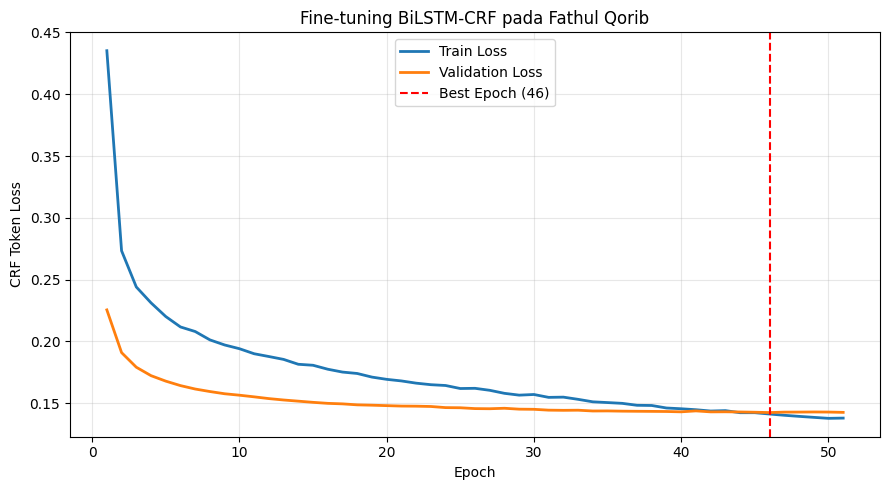

Epoch terbaik    : 46
Validation loss : 0.1425
Grafik tersimpan : /content/drive/MyDrive/BiLSTM-CRF/evaluation/finetuned/finetuning_curve.png
✓ Cell 12 berhasil dijalankan.


In [ ]:
history_df = pd.read_csv(HISTORY_PATH)

assert history_df["epoch"].is_unique
assert history_df["epoch"].min() == 1
assert history_df["epoch"].max() == 51

best_row = history_df.loc[
    history_df["validation_loss"].idxmin()
]

best_epoch_from_history = int(best_row["epoch"])
best_loss_from_history = float(
    best_row["validation_loss"]
)

assert best_epoch_from_history == 46

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss",
    linewidth=2,
)

plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation Loss",
    linewidth=2,
)

plt.axvline(
    best_epoch_from_history,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch_from_history})",
)

plt.xlabel("Epoch")
plt.ylabel("CRF Token Loss")
plt.title("Fine-tuning BiLSTM-CRF pada Fathul Qorib")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CURVE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Epoch terbaik    :", best_epoch_from_history)
print(
    "Validation loss :",
    round(best_loss_from_history, 4),
)
print("Grafik tersimpan :", CURVE_PATH)
print("✓ Cell 12 berhasil dijalankan.")

**Cell 13: Memuat dan memvalidasi model terbaik**

In [ ]:
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False,
)

assert best_checkpoint["epoch"] == 46
assert (
    best_checkpoint["source_dataset"]
    == "Tashkeela -> Fathul Qorib"
)
assert best_checkpoint["char2id"] == char2id
assert best_checkpoint["label2id"] == label2id
assert best_checkpoint["pretrained_epoch"] == 62

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()

recalculated_validation_loss = run_epoch(
    validation_loader,
    training=False,
)

saved_validation_loss = float(
    best_checkpoint["validation_loss"]
)

assert abs(
    recalculated_validation_loss
    - saved_validation_loss
) < 1e-4

print("Checkpoint epoch        :", best_checkpoint["epoch"])
print("Pretrained epoch        :", best_checkpoint["pretrained_epoch"])
print(
    "Saved validation loss  :",
    round(saved_validation_loss, 4),
)
print(
    "Checked validation loss:",
    round(recalculated_validation_loss, 4),
)
print("Model fine-tuning terbaik berhasil dimuat.")
print("✓ Cell 13 berhasil dijalankan.")

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Checkpoint epoch        : 46
Pretrained epoch        : 62
Saved validation loss  : 0.1425
Checked validation loss: 0.1425
Model fine-tuning terbaik berhasil dimuat.
✓ Cell 13 berhasil dijalankan.


**Cell 14: Menyimpan konfigurasi dan audit**

In [ ]:
finetuning_config = {
    "model_name": "BiLSTM-CRF Fine-tuned",
    "training_flow": "Tashkeela -> Fathul Qorib",
    "seed": SEED,
    "vocabulary_size": len(char2id),
    "number_of_labels": len(label2id),
    "max_sequence_length": MAX_LEN,
    "embedding_dimension": EMBEDDING_DIM,
    "hidden_dimension": HIDDEN_DIM,
    "number_of_lstm_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam baru",
    "learning_rate": LEARNING_RATE,
    "loss_reduction": "token_mean",
    "gradient_clip": GRAD_CLIP,
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "minimum_improvement": MIN_DELTA,
    "pretrained_epoch": PRETRAINED_EPOCH,
    "initial_fathul_validation_loss": float(
        initial_fathul_validation_loss
    ),
    "completed_epochs": int(
        history_df["epoch"].max()
    ),
    "best_epoch": int(
        best_checkpoint["epoch"]
    ),
    "best_validation_loss": float(
        best_checkpoint["validation_loss"]
    ),
    "train_pages": int(
        train_data["page"].nunique()
    ),
    "train_sequences": int(len(train_data)),
    "validation_pages": int(
        validation_data["page"].nunique()
    ),
    "validation_sequences": int(
        len(validation_data)
    ),
    "all_layers_finetuned": True,
    "optimizer_state_reused": False,
    "uses_test_data": False,
}

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        finetuning_config,
        file,
        ensure_ascii=False,
        indent=2,
    )


required_outputs = [
    BEST_MODEL_PATH,
    FINAL_CHECKPOINT_PATH,
    CONFIG_PATH,
    HISTORY_PATH,
    CURVE_PATH,
]

for file_path in required_outputs:
    assert file_path.exists()
    assert file_path.stat().st_size > 0


training_audit = {
    "status": "passed",
    "pretrained_weights_loaded": True,
    "mapping_compatible": True,
    "optimizer_reset": True,
    "all_layers_finetuned": True,
    "best_model_loadable": True,
    "validation_loss_verified": True,
    "test_data_used": False,
    "pretrained_epoch": PRETRAINED_EPOCH,
    "best_finetuning_epoch": int(
        best_checkpoint["epoch"]
    ),
    "best_validation_loss": float(
        best_checkpoint["validation_loss"]
    ),
}

with open(
    AUDIT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_audit,
        file,
        ensure_ascii=False,
        indent=2,
    )


print("Status audit            :", training_audit["status"])
print("Model                   : BiLSTM-CRF Fine-tuned")
print("Pretrained epoch        :", PRETRAINED_EPOCH)
print("Fine-tuning selesai     :", finetuning_config["completed_epochs"])
print("Fine-tuning terbaik     :", finetuning_config["best_epoch"])
print(
    "Validation loss terbaik:",
    round(
        finetuning_config["best_validation_loss"],
        4,
    ),
)
print("Semua layer dilatih     : Ya")
print("Test data digunakan     : Tidak")
print("Model terbaik           :", BEST_MODEL_PATH)
print("✓ Notebook 04 selesai dan tervalidasi.")

Status audit            : passed
Model                   : BiLSTM-CRF Fine-tuned
Pretrained epoch        : 62
Fine-tuning selesai     : 51
Fine-tuning terbaik     : 46
Validation loss terbaik: 0.1425
Semua layer dilatih     : Ya
Test data digunakan     : Tidak
Model terbaik           : /content/drive/MyDrive/BiLSTM-CRF/models/finetuned/best_finetuned_model.pt
✓ Notebook 04 selesai dan tervalidasi.
